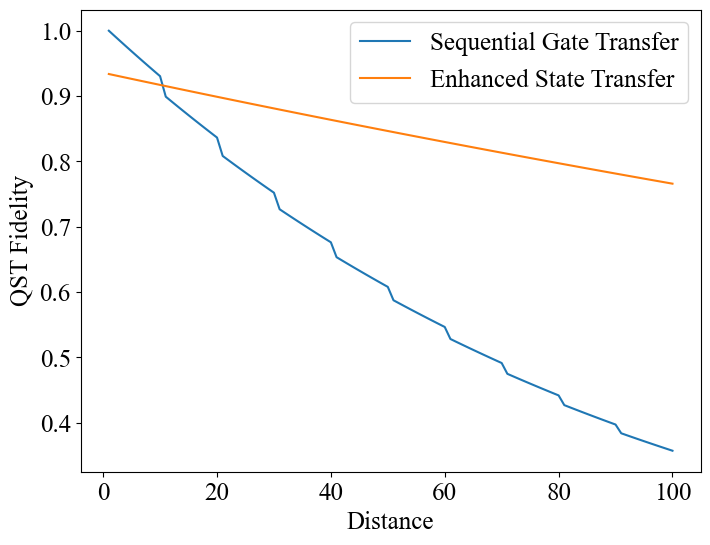

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'times new roman'
plt.rcParams['font.size'] = 18

x = np.linspace(1, 100, 100)
y1 = 0.996**(2*(x-1-(x-1)//10))*0.983**(2*((x-1)//10))
y2 = 0.983**4*0.998**(x-1)

fig = plt.figure(figsize=(8, 6))

plt.plot(x, y1, label='Sequential Gate Transfer')
plt.plot(x, y2, label='Enhanced State Transfer')
plt.xlabel('Transfer Distance')
plt.ylabel('Process Fidelity')
plt.legend()
plt.show()

Fitting parameters: [0.75370332 0.99687498]


/var/folders/9l/ptdyklz52vg1558_48z8l4qc0000gn/T/ipykernel_92268/2337089415.py:12: OptimizeWarning: Covariance of the parameters could not be estimated
  params, _ = curve_fit(


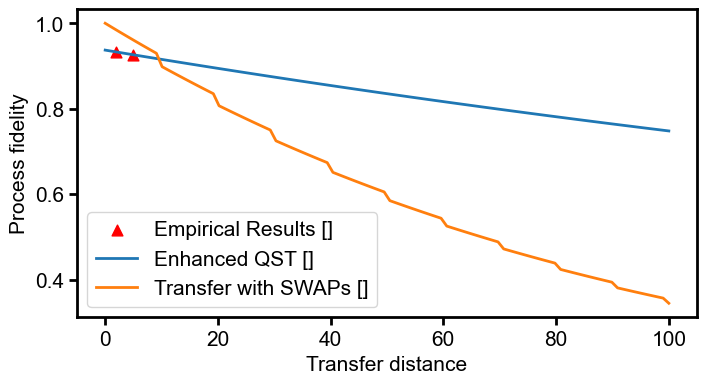

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

plt.rcParams['font.family'] = 'arial'
plt.rcParams['font.size'] = 15

dist = [2, 5]
eqst_fide = [0.999, 0.992]
def eqst_fide_curve(x, A, P):
    return A * (P**x) + 0.25
params, _ = curve_fit(
    eqst_fide_curve,
    np.array(dist),
    np.array(eqst_fide),
    p0=[0.01, 0.01],
)
print('Fitting parameters:', params)

x_dist = np.linspace(0, 100, 100)
y_eqst = 0.983**4*eqst_fide_curve(x_dist, *params)
y_swap = 0.996**(2*(x_dist-x_dist//10))*0.983**(2*(x_dist//10))

fig, ax = plt.subplots(figsize=(8, 4))

for spine in ax.spines.values():
    spine.set_linewidth(2)
ax.tick_params(axis='both', width=2, length=6)

plt.scatter(dist, 0.983**4*np.array(eqst_fide), color='red', marker='^', s=60, label='Empirical Results []')
plt.plot(x_dist, y_eqst, linewidth=2, label='Enhanced QST []')
plt.plot(x_dist, y_swap, linewidth=2, label='Transfer with SWAPs []')
plt.xlabel('Transfer distance')
plt.ylabel('Process fidelity')
plt.legend()
plt.savefig('fide_motivate.svg', bbox_inches='tight')